# Filtrando reseñas de películas

Film Junky Union es una nueva comunidad vanguardista para los aficionados de las películas clásicas, está desarrollando un sistema para filtrar y categorizar reseñas de películas. El objetivo del proyecto es entrenar un modelo para detectar las críticas negativas de forma automática. Para lograrlo, se proporciona un conjunto de datos de reseñas de películas de IMDB con leyendas de polaridad para construir un modelo para clasificar las reseñas positivas y negativas. La metrica solicitada es alcanzar un valor de al menos 0.85 de F1.

# Contenido <a id='back'></a>

* [1. Inicialización](#start) 
* [2. Carga de datos](#data_entry)
* [3. Analisis Exploratorio de Datos (EDA)](#eda)
* [4. Métricas de evaluación de modelos](#metricas)
* [5. Normalización de características](#normalization)
* [6. Desarrollo de modelos](#models)
    * [6.1 Modelo 0 - Constante](#constante)
    * [6.2 Modelo 1 - NLTK, TF-IDF y LR](#modelo1)
    * [6.3 Modelo 2 - spaCy, TF-IDF y LR](#modelo2)
    * [6.4 Modelo 3 - spaCy, TF-IDF y LGBMClassifier](#modelo3)
    * [6.5 Modelo 4 - BERT](#modelo4)
* [7. Reseñas propias](#my_review)
    * [7.1 Prueba modelo 1](#proveM1)
    * [7.2 Prueba modelo 3](#proveM3)
    * [7.3 Prueba modelo 4](#proveM4)
    * [7.4 Prueba modelo 5](#proveM5)
* [8. Conclusiones](#end)

## Inicialización <a id='start'></a>

In [56]:
#importacion de las librerias que usaremos
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

import re

In [57]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# la siguiente línea proporciona gráficos de mejor calidad en pantallas HiDPI
# %config InlineBackend.figure_format = 'retina'

#plt.style.use('seaborn')
plt.style.use('seaborn-v0_8')

In [58]:
# esto es para usar progress_apply, más info en https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Cargar datos <a id='data_entry'></a>

In [59]:
#cargar datos con separador de tab y cambio de formato de votos a interger
df_reviews = pd.read_csv('imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

In [60]:
#lectura de primeros datos
df_reviews.head()

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281


In [61]:
# informacion del dataset
df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331 non-null  int64  
dtypes: Int64(1),

In [62]:
#comprobar si existen duplicados
df_reviews.duplicated().sum()

np.int64(0)

In [63]:
df_reviews.duplicated('idx').sum()

np.int64(34831)

In [64]:
df_reviews.duplicated('tconst').sum()

np.int64(40683)

In [65]:
df_reviews[df_reviews.duplicated(['tconst', 'idx'])]

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
37685,tt0406816,movie,The Guardian,The Guardian,2006,\N,139,0,"Action,Adventure,Drama",6.9,85875,My yardstick for measuring a movie's watch-abi...,7,pos,1,test,2
37686,tt0406816,movie,The Guardian,The Guardian,2006,\N,139,0,"Action,Adventure,Drama",6.9,85875,How many movies are there that you can think o...,7,pos,1,test,3
37687,tt0406816,movie,The Guardian,The Guardian,2006,\N,139,0,"Action,Adventure,Drama",6.9,85875,I only went to see this movie because I have a...,7,pos,1,test,5
37697,tt0406816,movie,The Guardian,The Guardian,2006,\N,139,0,"Action,Adventure,Drama",6.9,85875,I went and saw this movie last night after bei...,10,pos,1,test,0
37699,tt0406816,movie,The Guardian,The Guardian,2006,\N,139,0,"Action,Adventure,Drama",6.9,85875,My boyfriend and I went to watch The Guardian....,10,pos,1,test,1
37700,tt0406816,movie,The Guardian,The Guardian,2006,\N,139,0,"Action,Adventure,Drama",6.9,85875,This movie was sadly under-promoted but proved...,10,pos,1,test,4


In [66]:
df_reviews[df_reviews.duplicated(['review'])]

#Existen reseñas duplicada, puede deberse a que ya existe un balanceo de clases, a comprobar

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
1370,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,I have seen this film at least 100 times and I...,10,pos,1,test,9768
1630,tt0098994,movie,"After Dark, My Sweet","After Dark, My Sweet",1990,\N,114,0,"Crime,Drama,Mystery",6.6,3098,THE JIST: See something else. This film was hi...,7,pos,1,train,7729
1983,tt0115509,movie,All Dogs Go to Heaven 2,All Dogs Go to Heaven 2,1996,\N,82,0,"Adventure,Animation,Family",5.5,5396,This movie is very scary with scenes where the...,1,neg,0,test,7914
2132,tt0092545,movie,Amazing Grace and Chuck,Amazing Grace and Chuck,1987,\N,114,0,"Drama,Sport",6.0,1235,I saw this in the summer of 1990. I'm still an...,1,neg,0,train,6320
2236,tt0181288,movie,American Movie,American Movie,1999,\N,107,0,"Comedy,Documentary",7.9,16416,This is an Emperor's New Clothes situation. So...,1,neg,0,test,1470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46064,tt0038245,movie,Where Do We Go from Here?,Where Do We Go from Here?,1945,\N,74,0,"Fantasy,Musical",5.8,220,"During a Kurt Weill celebration in Brooklyn, W...",8,pos,1,train,4267
47052,tt0365960,movie,Zero Day,Zero Day,2002,\N,92,0,Drama,7.2,3947,Everyone knows about this ''Zero Day'' event. ...,10,pos,1,train,11470
47194,tt0463392,movie,Zombie Nation,Zombie Nation,2004,\N,81,0,Horror,2.0,7850,German filmmaker Ulli Lommel has managed a tas...,1,neg,0,train,10108
47290,tt0972534,tvSeries,iCarly,iCarly,2007,2012,30,0,"Comedy,Family,Romance",6.6,31143,Nickelodeon has gone down the toilet. They hav...,1,neg,0,test,5655


In [67]:
#para saber que proporcion de valores hay en cuanto a reseñas
df_reviews['pos'].value_counts()

#se confirma que ya se ha realizado un balanceo de clases. No se considera entonce borrar los duplicados

pos
0    23715
1    23616
Name: count, dtype: int64

In [68]:
df_reviews.query('tconst == "tt0081949"')

#Observamos que el tconst pertenece a cada una de las series

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
1358,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,"If you love the book, as I do, stop watching t...",7,pos,1,test,9761
1359,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,I raced to the library to check out this minis...,7,pos,1,test,9766
1360,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,This is one of my favourite books and I rememb...,8,pos,1,test,9762
1361,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,This review contains what might be a spoiler i...,9,pos,1,test,9763
1362,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,Apparently this Australian film based on Nevil...,9,pos,1,test,9769
1363,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,"I don't know where this movie was shot, but be...",10,pos,1,test,9757
1364,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,I cannot believe it has been 25 yrs since I fi...,10,pos,1,test,9758
1365,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,"Jean Paget, Joe Harman, and Noel Strachan--all...",10,pos,1,test,9759
1366,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,"I can't count the times I have watched this, a...",10,pos,1,test,9760
1367,tt0081949,tvMiniSeries,A Town Like Alice,A Town Like Alice,1981,1981,301,0,"Drama,Romance,War",8.3,849,This movie is a sleeper - I've watched every m...,10,pos,1,test,9764


In [69]:
#revisar datos ausentes
df_reviews.isna().sum()

tconst             0
title_type         0
primary_title      0
original_title     0
start_year         0
end_year           0
runtime_minutes    0
is_adult           0
genres             0
average_rating     2
votes              2
review             0
rating             0
sp                 0
pos                0
ds_part            0
idx                0
dtype: int64

In [70]:
#se eliminan los datos faltantes (2)
df_reviews.dropna(inplace=True)
#se comprueba no datos nulos
df_reviews.isna().sum()

tconst             0
title_type         0
primary_title      0
original_title     0
start_year         0
end_year           0
runtime_minutes    0
is_adult           0
genres             0
average_rating     0
votes              0
review             0
rating             0
sp                 0
pos                0
ds_part            0
idx                0
dtype: int64

In [71]:
# se contabilizan las reseñas de cada titulo
df_reviews['primary_title'].value_counts()

primary_title
The Sentinel                  60
The War at Home               54
Emma                          51
Jane Eyre                     49
In Cold Blood                 42
                              ..
La Commune (Paris, 1871)       1
La Fiesta de Santa Barbara     1
The Lavender Hill Mob          1
La bandera                     1
My Friend Flicka               1
Name: count, Length: 6554, dtype: int64

## Analisis Exploratorio de Datos (EDA) <a id='eda'></a>

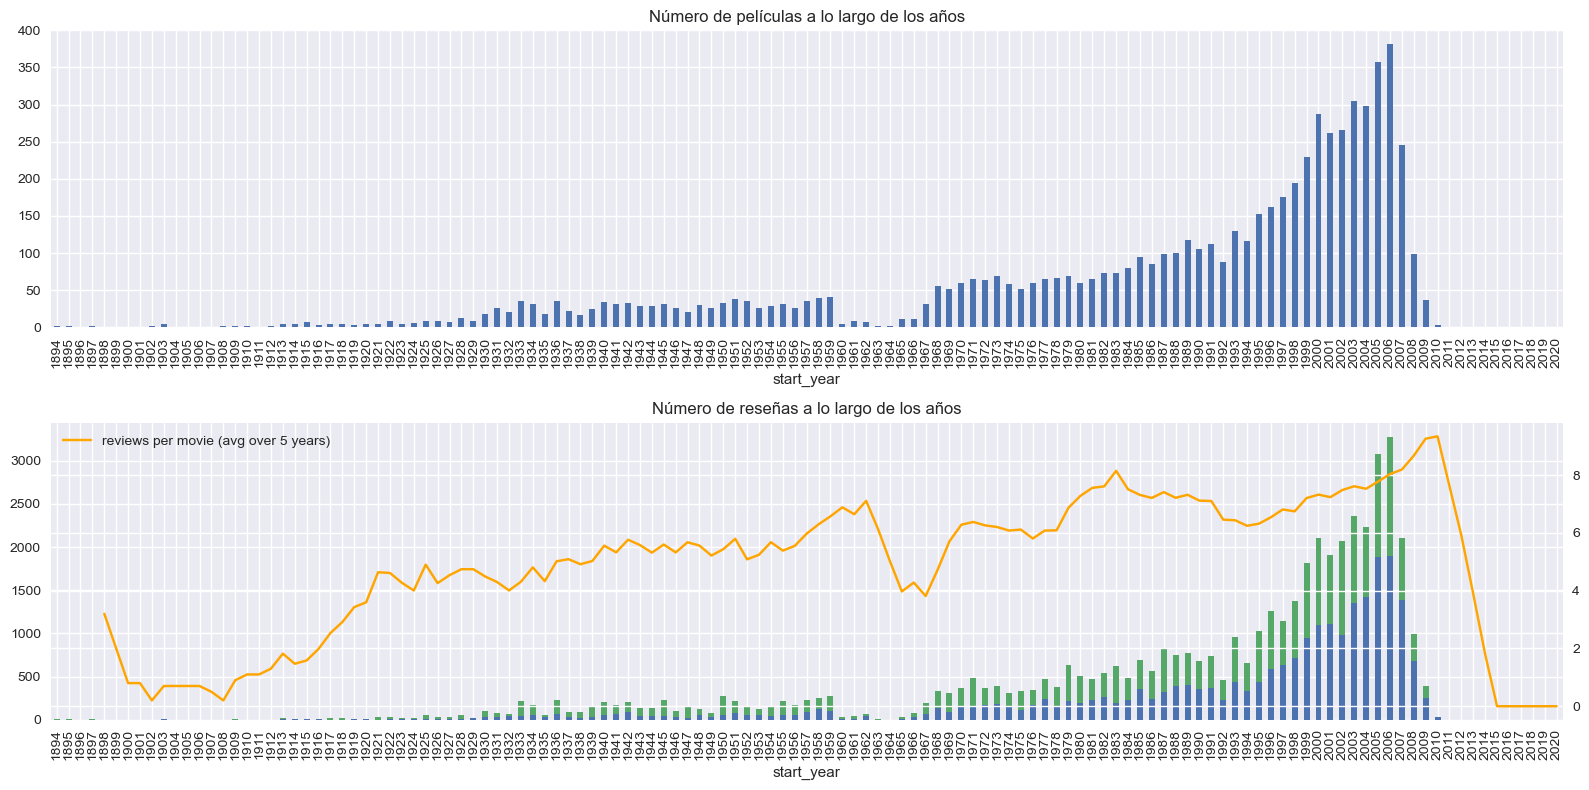

In [72]:
#Grafica del número de películas y reseñas a lo largo de los años.
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de películas a lo largo de los años')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='reviews per movie (avg over 5 years)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de reseñas a lo largo de los años')

fig.tight_layout()

Se puede observar que existen menos de 50 peliculas por años desde 1894 hasta 1968, después de esta año hay un incremento constante de peliculas hasta 2006 con casi 400 peliculas en ese año, posterior a eso la contabilización disminuye.

Por parte del número de reseñas por año, hasta 1979 s tienen menos de 500 reseñas por año, despues de 1976 incrementaron de forma constante las reseñas hasta tener un poco de casi 3000 reseñas en el año 2006, en naranja se observa la linea que promedia el numero de reseñas por peliculas en los ultimos 5 años, donde a partir de 1921 se tienen mas de 4 reseñas por película y se tiene un maximo de 8 reseñas pasado el 2011.

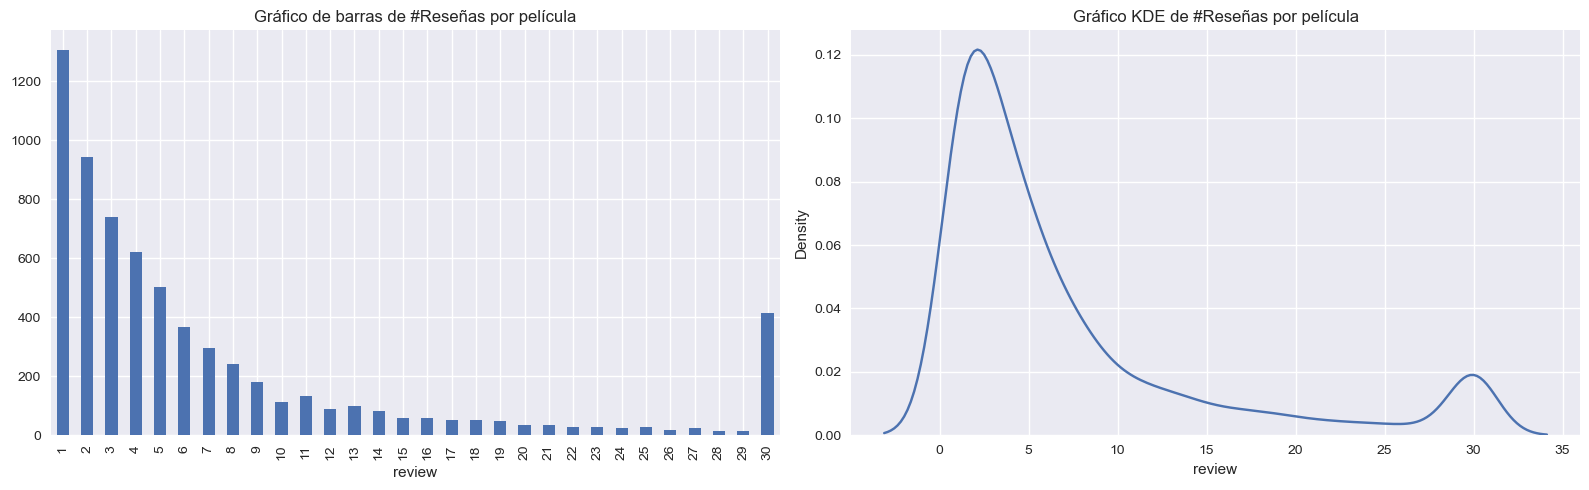

In [73]:
#Grafica de la distribución del número de reseñas por película con el conteo exacto y KDE (solo para saber cómo puede diferir del conteo exacto)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de barras de #Reseñas por película')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico KDE de #Reseñas por película')

fig.tight_layout()

Del grafico de barras de reseñas por películas, se observa que la mayoria de peliculas cuentan con una a cinco reseñas, tenemos una distribución de cola larga, donde las peliculas que cuentan con 10 reseñas en adelante son menos de 200 películas, lo que nos describe que la mayoria de las peliculas son poco conocidas y reciben menos de 5 reseñas, existen mas de 1200 películas con una sola reseña, cabe destacar que se observa un dato fuera de la rendencia en el valor de 30 reselas que llega a casi 400 películas con este numero de reseñas, un repunte abrupto o segundo pico, eso se puede deber a una restricción técnica, un límite máximo de reseñas o una agrupación que contabilice en forma de "30 reseñas o mas".

In [74]:
#observamos si hay un equilibrio de clases para reseñas positivas y negativas
df_reviews['pos'].value_counts()

pos
0    23715
1    23614
Name: count, dtype: int64

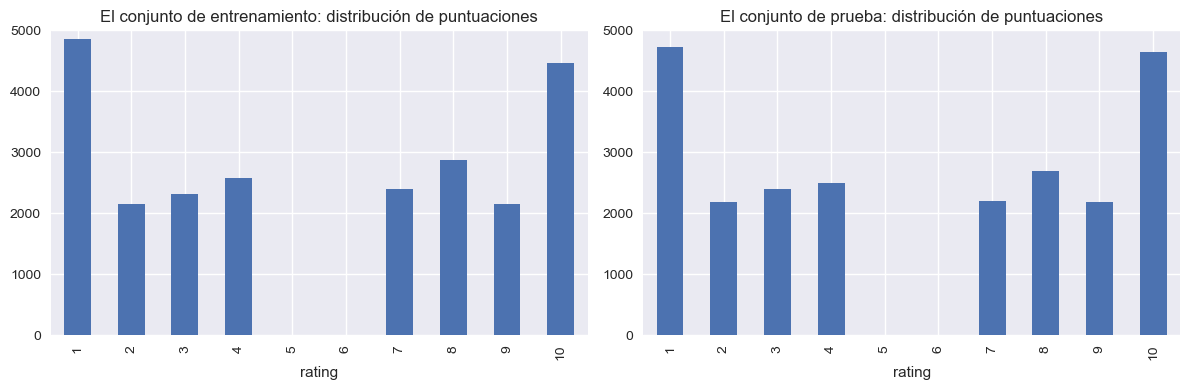

In [75]:
# Grafica para visualizar distribucion de reseñas positivas y negativas en el conjunto de entrenamiento y prueba
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de entrenamiento: distribución de puntuaciones')

ax = axs[1]  
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de prueba: distribución de puntuaciones')

fig.tight_layout()

Se observa que existe un desequilibrio de clases para el rating tanto positivo como negativo en ambos conjuntos de prueba y entrenamiento, los datos no siguen una distribucion uniforma, existe una mayor tendencia de raiting de 1 y 10, siento estos de casi 5000 datos, mientras que no existe registro para raitings de 5 y 6, otras calificaciones de 2 a 9 se encuentran entre 2000 y 3000 entradas. De igual forma podemos ver que la division de datos para entrenamiento y prueba contienen ambos la misma estructura de raiting.

C:\Users\Administrator\AppData\Local\Temp\ipykernel_656\3527140615.py:15: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_656\3527140615.py:16: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_656\3527140615.py:31: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_656\3527140615.py:32: User

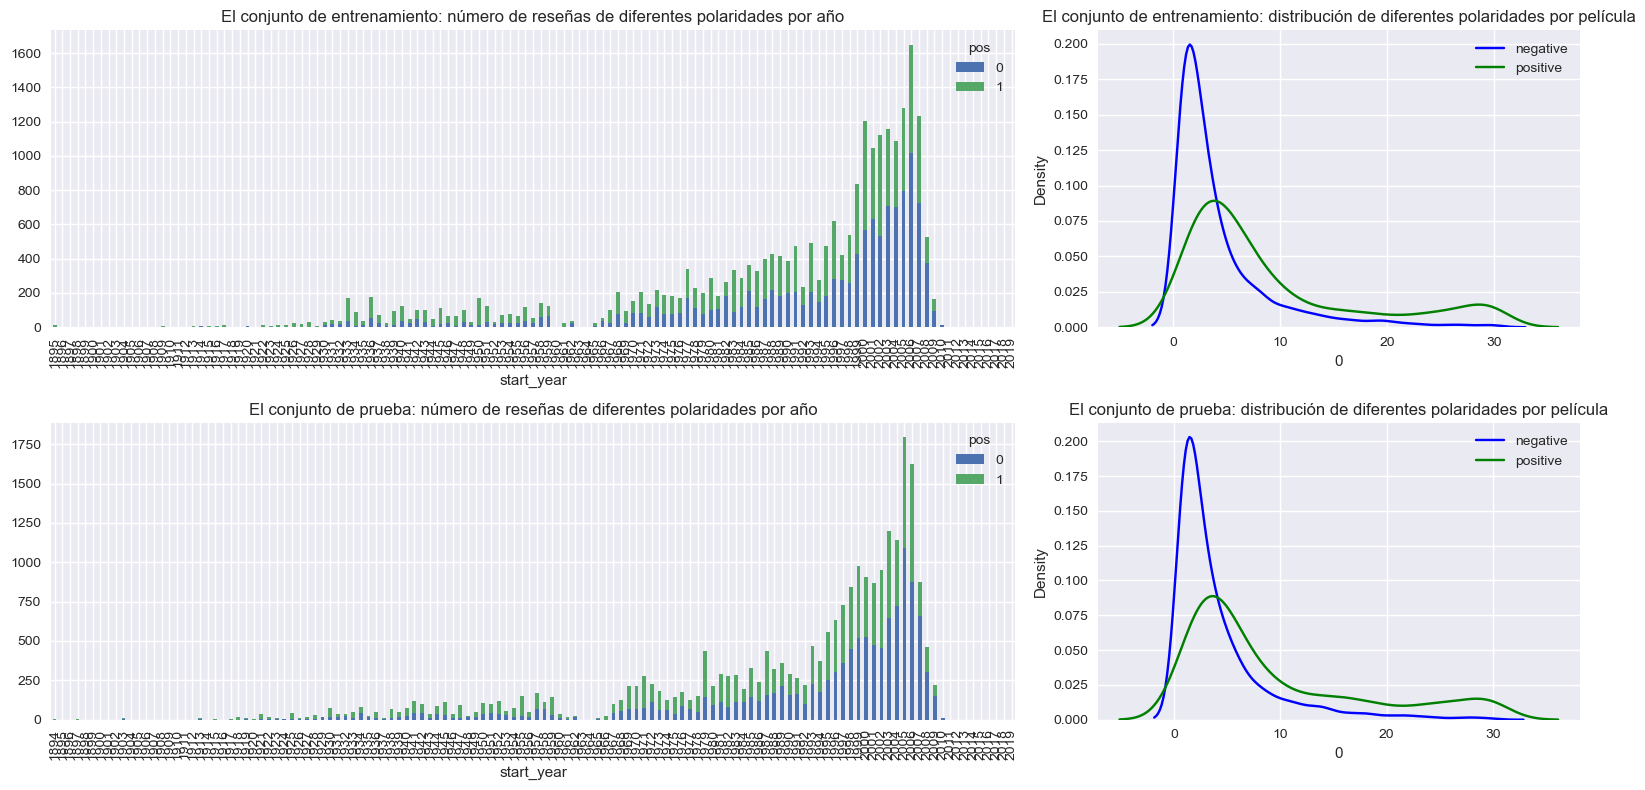

In [76]:
#Distribución de reseñas negativas y positivas a lo largo de los años para dos partes del conjunto de datos
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de entrenamiento: número de reseñas de diferentes polaridades por año')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de entrenamiento: distribución de diferentes polaridades por película')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de prueba: número de reseñas de diferentes polaridades por año')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de prueba: distribución de diferentes polaridades por película')

fig.tight_layout()

En estas graficas de reseñas por año y la polaridad entre positivas y negativas, se vuelve a observar una simetria perfecta entre los datos de entrenamiento y los datos de prueba, esto demuestra que el existe una division correcta entre los conjuntos conservando la misma extructura temporal, proporciones de polaridad y distribucion de densidad. Podemos observar que antes de 1995 el numero de reseñas por año no super las 500 reseñas, y a partit de 1995 existe un crecimiento exponencial de numero se reseñas hasta llegar a 2006 año en el que se registran mas de 1750 reseñas, posteriormente existe una diminución abrupta. De igual forma la distribucion de reseñas positivas y negativas es casi 50/50 por lo que existe un equilibrio en estas clases. 

Por parte de la densidad de reseñas se observa como la curva azul tiene un pico mucho más alto y estrecho cerca del valor cero. Esto significa que hay una enorme cantidad de películas que reciben muy pocas reseñas negativas (la insatisfacción se concentra con fuerza en pocas películas o la gente prefiere no reseñar lo que no le gusta) mientras que la curva verde es más baja, ancha y se extiende más hacia la derecha. Esto nos dice que las reseñas positivas se distribuyen de forma más homogénea y alcanzan volúmenes más altos por película con mayor facilidad.

Con esto podemos confirmar que los datos están listos, limpios y equilibrados para entrenar un modelo de clasificación de texto o análisis de sentimiento. Al estar las clases tan bien distribuidas en ambos conjuntos, se puede utilizar la métrica de Exactitud (Accuracy) o F1-Score de forma directa sin temor a que el modelo esté sesgado hacia una polaridad en particular.

## Métricas de evaluación de modelos <a id='metricas'></a>

In [77]:
#Evaluacion de los modelos mediante las metricas F1, auc-roc, PRC, una rutina de evaluacion para todos los modelos. 
import sklearn.metrics as metrics
def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):

        eval_stats[type] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]

        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)
        eval_stats[type]['ROC AUC'] = roc_auc

        # PRC
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps

        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1')

        # ROC
        ax = axs[1]
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title(f'Curva ROC')

        # PRC
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)

    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))

    print(df_eval_stats)

    return

## Normalización de características <a id='normalization'></a>

La normalización es un paso importante para evitar "ruido" en los datos y estandarizar el hecho que las palabras estén en casos escritas con mayúsculas y en otros con minúsculas. Suponemos que todos los modelos a continuación aceptan textos en minúsculas y sin dígitos, signos de puntuación, etc.

In [78]:
#Normalizar texto a puras minusculas
df_reviews['review_norm'] = df_reviews['review'].str.lower().apply(lambda fila: re.sub(r'[^a-z]', ' ', fila)) 
print(df_reviews['review_norm'])

0        the pakage implies that warren beatty and gold...
1        how the hell did they get this made   presenti...
2        there is no real story the film seems more lik...
3        um      a serious film about troubled teens in...
4        i m totally agree with garryjohal from singapo...
                               ...                        
47326    this is another of my favorite columbos  it sp...
47327    talk about being boring  i got this expecting ...
47328    i never thought i d say this about a biopic  b...
47329    spirit and chaos is an artistic biopic of miya...
47330    i ll make this brief  this was a joy to watch ...
Name: review_norm, Length: 47329, dtype: object


Todo el conjunto de datos ya está dividido en partes de entrenamiento/prueba; 'ds_part' es el indicador correspondiente.

## Desarrollo de modelos <a id='models'></a>

In [79]:
#Division de seccion de datos destinados a entrenamiento y a prueba
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

df_reviews_train= df_reviews_train.drop(['sp', 'pos'], axis=1)
df_reviews_test = df_reviews_test.drop(['sp', 'pos'], axis =1)

(23796, 18)
(23533, 18)


### Modelo 0 - Constante <a id='constante'></a>

In [80]:
# Se importa DummyClassifier, un modelo "tonto" diseñado para servir como línea base
# estadística y comparar el rendimiento real de los algoritmos de Machine Learning.
from sklearn.dummy import DummyClassifier

In [81]:
# Se instancia el clasificador configurando la estrategia en 'constant' con valor 1.
# Esto significa que el modelo predecirá SIEMPRE que la reseña es POSITIVA (clase 1)
dummy_clf = DummyClassifier(strategy = 'constant', constant=1)

In [82]:
# Se "entrena" el modelo en el conjunto de datos de entrenamiento. En este caso,
# el ajuste (.fit) solo sirve para que el modelo registre las dimensiones de los datos.
model_0 = dummy_clf.fit(df_reviews_train, train_target)

          train  test
Accuracy   0.50  0.50
F1         0.67  0.67
APS        0.50  0.50
ROC AUC    0.50  0.50


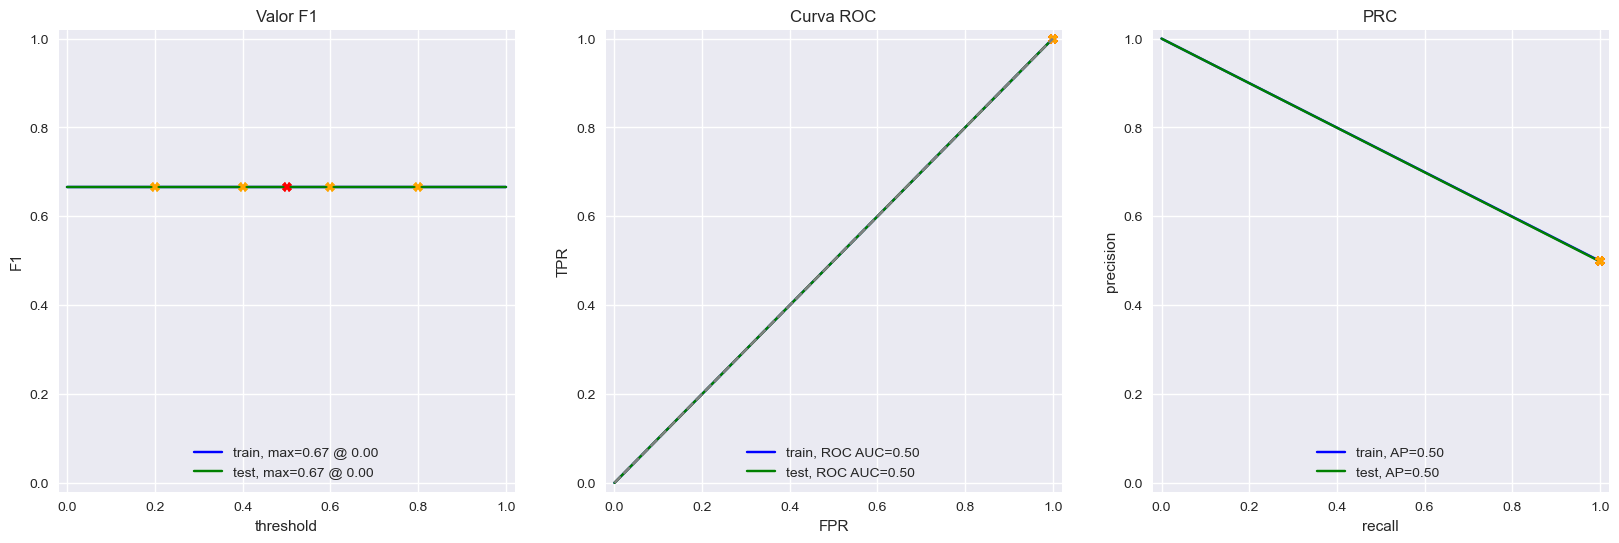

In [83]:
# Se ejecuta la función personalizada para evaluar el rendimiento del modelo base.
# Compara las predicciones constantes (todas 1) contra los valores reales de entrenamiento y prueba,
# imprimiendo métricas como Accuracy, F1-Score y la Matriz de Confusión para contextualizar los resultados.
evaluate_model(model_0, df_reviews_train, train_target, df_reviews_test, test_target)

El modeo dummy tiene resultados constantes para predecir siempre la clase 1, y al tener un conjunto de datos equilibrado hace que los resultados den 50/50 de probabilidad, de las graficas confirman que el modelo dummy no es predictivo, ya que es simple azar. 
La primera grafica de valor de F1 es plana debido a que no importa el umbral en el que se mueva, la prediccion siempre sera la misma. El valor de F1 es de 0.67 esto se entiende porque como el modelo dice que todo es positivo, su Recall (Exhaustividad) es de 1.0 (100%): atrapó todas las reseñas positivas reales, sin embargo su precisión es de 0.50 (50%): de todo lo que dijo que era positivo, solo la mitad lo era realmente , por lo que la media armónica entre 1.0 y 0.50 da exactamente 0.67.
El modelo al predecir todos los datos como clase 1, y al tener un equilibrio de clases, el modelo solo acierta correctamente a los valores de clase 1, esto cofirma que tenemos un equilibrio de clases tanto en el conjunto de prueba como en el de entrenamiento. La grafica de AUC-ROC es una linea perfecta de 0-0 a 1-1, el area bajo la curva es de 0.5 por lo que es incapaz de distinguir entre una reseña positiva y una reseña negativa.


### Modelo 1 - NLTK, TF-IDF y LR <a id='modelo1'></a>

Un modelo compuesto por NLTK, TF-IDF y LR es uno de los pipelines mas eficientes para resolver problemas de Análisis de Sentimiento y Clasificación de Texto. NLTK (Natural Language Toolkit) es la librería de Python que se encarga de la limpieza inicial o preprocesamiento. 

TF-IDF se refiere a Term Frequency - Inverse Document Frequency es un algoritmo de vectorización que convierte los textos limpios en números, asignando un peso o importancia a cada palabra basándose en una regla inteligente de dos partes: 1) TF (Frecuencia del Término): Entre más veces aparezca una palabra dentro de una reseña específica, más importante es para esa reseña y 2) IDF (Frecuencia Inversa de Documento): Si una palabra aparece en absolutamente todas las reseñas del dataset (como la palabra "película" o "actor"), su importancia disminuye drásticamente porque no ayuda a diferenciar una opinión de otra. En cambio, si palabras como "espectacular" o "pésima" aparecen solo en algunos documentos, reciben un peso matemático muy alto.

Una vez que TF-IDF convirtió la reseña en una larga fila de números donde cada columna es el peso de una palabra, la Regresión Logística entra como modelo predictivo al ser un algoritmo de clasificación binaria que analiza estadísticamente los pesos de las palabras de entrenamiento para encontrar patrones. El algoritmo prende cuáles palabras tienen coeficientes positivos (asociadas a la clase 1 o reseñas positivas) y cuáles tienen coeficientes negativos (asociadas a la clase 0 o reseñas negativas).


In [84]:
#PIPELINE DE NLP: VECTORIZACIÓN TF-IDF Y REGRESIÓN LOGÍSTICA
# Se importa la librería NLTK (Natural Language Toolkit) para el procesamiento de texto
import nltk
# Se importa TfidfVectorizer para convertir texto en una matriz de características numéricas
# basándose en la relevancia de las palabras (Frecuencia de Término - Frecuencia Inversa de Documento)
from sklearn.feature_extraction.text import TfidfVectorizer
# Se importa el algoritmo de Regresión Logística, muy eficiente para clasificación de texto binaria
from sklearn.linear_model import LogisticRegression
# Se importa el módulo de palabras vacías (stop words) de NLTK
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Administrator\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [85]:
# Se inicializa el vectorizador configurando dos parámetros críticos: stop_words: Elimina conectores comunes en inglés que no aportan significado (ej. 'the', 'is', 'and')
#  y  lowercase=True: Convierte todo el texto a minúsculas para unificar palabras idénticas (ej. 'Movie' y 'movie')
vectorizador_1 = TfidfVectorizer(stop_words=stopwords.words('english'), lowercase=True)

In [86]:
# El modelo analiza el vocabulario y entrena (.fit), para luego transformar (.transform) 
# las reseñas limpias de entrenamiento ('review_norm') en una matriz numérica dispersa.
train_features_1 = vectorizador_1.fit_transform(df_reviews_train['review_norm'])

# Se transforman las reseñas del conjunto de prueba utilizando ÚNICAMENTE el vocabulario 
# aprendido en el paso anterior. (Importante: NO se usa .fit_transform aquí para evitar Data Leakage)
test_features_1 = vectorizador_1. transform(df_reviews_test['review_norm'])

In [87]:
# Se instancia el clasificador de Regresión Logística
model_1 = LogisticRegression()

In [88]:
# Se entrena el modelo de Regresión Logística utilizando las características TF-IDF y las etiquetas objetivo de entrenamiento
model_1.fit(train_features_1, train_target)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

          train  test
Accuracy   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


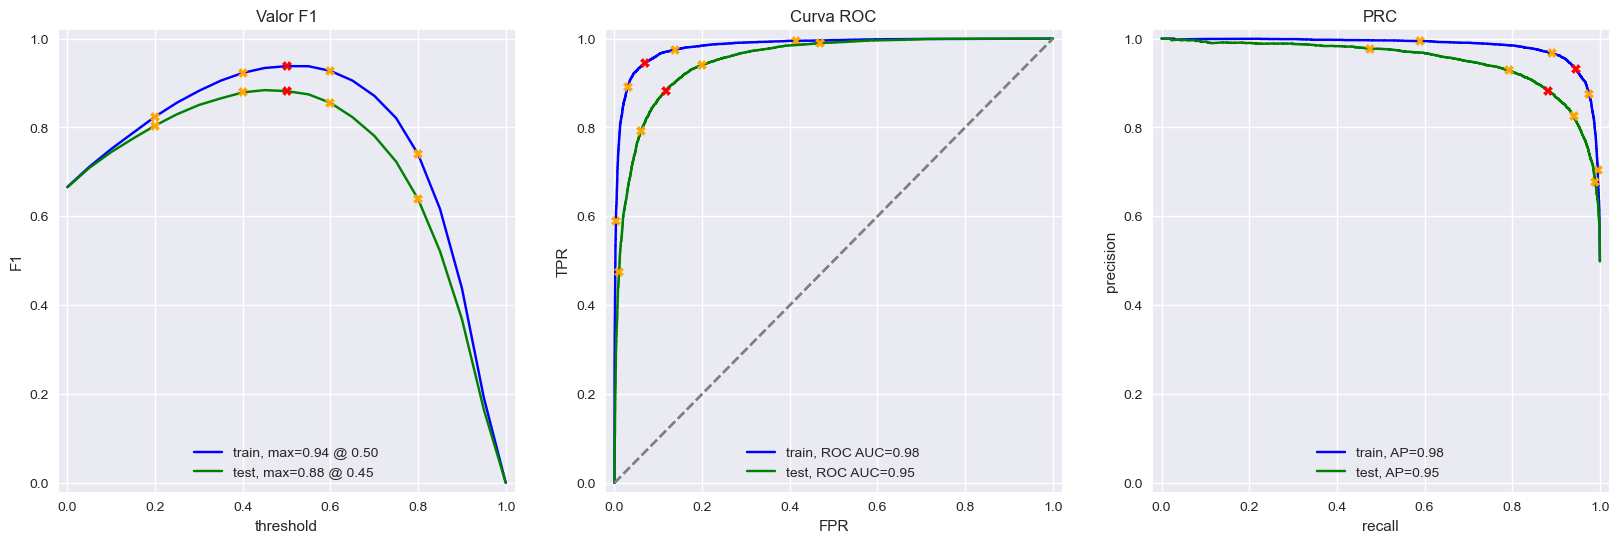

In [89]:
# Se evalúa el desempeño final del modelo entrenado tanto en el conjunto de entrenamiento como en el de prueba,
# lo que imprimirá métricas avanzadas (como Accuracy y F1-Score) para compararlo contra el baseline.
evaluate_model(model_1, train_features_1, train_target, test_features_1, test_target)

En comparación con el modelo constante, tiene mucho mejores resultados, e igual bastante buenos al comprbarlos con el conjunto de prueba. Se confirma que este algoritmo demuestra haber aprendido patrones lingüísticos reales y profundos para clasificar las reseñas. Se alcanza un rendimiento F1-score de 0.88 se logra un equilibrio optimo entre la precision de las reseñas que realmente son positivas y el recall, superando el limite minimo del azar. El resultado de AUC-ROC es de 95% lo que significa un area bajo la curva del 95% una capacidad de esa magnitud de separar y distnguir entre una reseña positiva y una reseña negativa.

Para conocer la estabilidad del modelo y si existe un overfitting se analiza la brecha entre la curva azul de entrenamiento y la curva verde de prueba, las curvas en las tres gráficas corren casi en paralelo y mantienen formas idénticas, esto nos demuestra que no hay sobreajuste.

### Modelo 2 - spaCy, TF-IDF y LR <a id='modelo2'></a>

Esta configuracion de modelo es una versión avanzada de Procesamiento de Lenguaje Natural (NLP). A diferencia del modelo básico con NLTK, este enfoque introduce lematización de vanguardia para reducir el vocabulario y hacer que el clasificador sea mucho más preciso y estable. spaCy es una librería para el procesamiento de texto, en este modelo, su función principal es la Lematización. TF-IDF es el Traductor Matemático a Nivel de Raíz, este se encarga de convertir las palabras en números con los que un algoritmo matemático pueda trabajar. La Regresión Logística realiza la clasificación binaria final donde se predice si es una reseña negativa o positiva.

In [90]:
# PIPELINE DE NLP AVANZADO: LEMATIZACIÓN CON SPACY Y VECTORIZACIÓN TF-IDF
# Se importa la librería spaCy, especializada en procesamiento de lenguaje natural industrial de alta velocidad
!pip install spacy
!python -m spacy download en_core_web_sm
import spacy
# Se carga el modelo lingüístico optimizado en inglés ('en_core_web_sm').
# Con 'disable' se apagan el analizador sintáctico ('parser') y el reconocedor de entidades ('ner')
# para acelerar drásticamente el tiempo de ejecución, ya que solo necesitamos lematizar.
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ------------ --------------------------- 3.9/12.8 MB 22.3 MB/s eta 0:00:01
     --------------------------- ------------ 8.9/12.8 MB 23.1 MB/s eta 0:00:01
     --------------------------------------  12.6/12.8 MB 23.8 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 20.6 MB/s  0:00:00
[+] Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [91]:
def text_preprocessing_2(text):
    """
    Procesa un texto reduciendo cada palabra a su forma base o raíz jurídica (Lematización).
    Ejemplo: 'running', 'ran', 'runs' se transforman todas en la raíz 'run'.
    """
    # Se procesa el texto a través del pipeline activo de spaCy para generar un objeto 'doc' enriquecido
    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop]
   # Lista de comprensión que extrae el lema (.lemma_) de cada uno de los tokens del texto
    tokens = [token.lemma_ for token in doc]
     # Se vuelven a unir las palabras raíz en una sola cadena de texto separada por espacios
    return ' '.join(tokens)

In [42]:
# Se aplica la función de lematización a cada fila del conjunto de entrenamiento y posteriormente al de prueba.
# '.progress_apply()' de la librería tqdm muestra una barra de progreso visual en la consola/Jupyter.
df_reviews_train['review_tokenizada']= df_reviews_train['review_norm'].progress_apply(lambda fila: text_preprocessing_3(fila))
df_reviews_test['review_tokenizada']= df_reviews_test['review_norm'].progress_apply(lambda fila: text_preprocessing_3(fila))

  0%|          | 0/23796 [00:00<?, ?it/s]

  0%|          | 0/23533 [00:00<?, ?it/s]

In [48]:
# Se inicializa el vectorizador TF-IDF configurado para eliminar las stop_words de NLTK y unificar minúsculas
vectorizador_2 = TfidfVectorizer(stop_words=stopwords.words('english'), lowercase=True)
# El vectorizador aprende el vocabulario lematizado y transforma el conjunto de entrenamiento en matrices numéricas
train_features = vectorizador_2.fit_transform(df_reviews_train['review_tokenizada'])
# Se transforma el conjunto de prueba utilizando únicamente el vocabulario lematizado aprendido previamente
test_features = vectorizador_2.transform(df_reviews_test['review_tokenizada'])

          train  test
Accuracy   0.93  0.88
F1         0.93  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


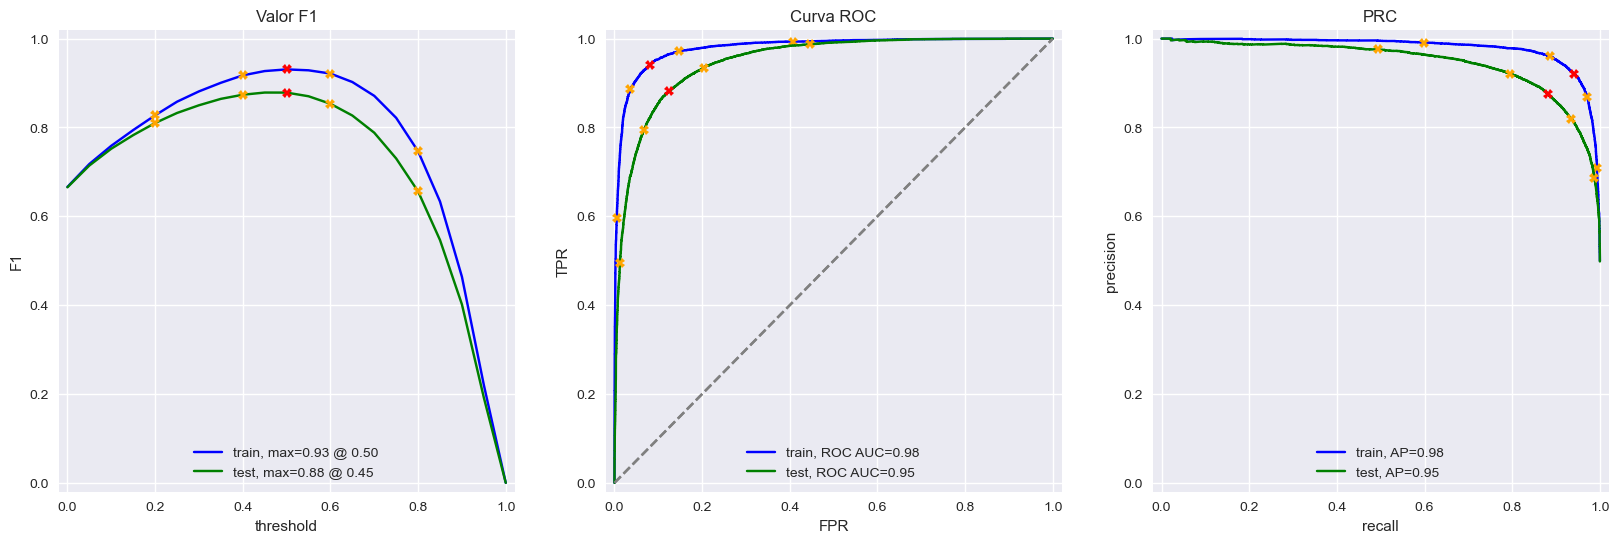

In [49]:
# Se instancia el clasificador de Regresión Logística para el nuevo set de datos optimizado
model_2 = LogisticRegression()
# Se entrena el modelo de Regresión Logística con las características lematizadas
model_2.fit(train_features, train_target)
# Se evalúa el desempeño final del modelo con el texto lematizado en los sets de entrenamiento y prueba,
# imprimiendo las métricas para verificar si la lematización mejoró el F1-Score respecto a la vectorización simple.
evaluate_model(model_2, train_features, train_target, test_features, test_target)

 Al probar spacy, el modelo tiene resultados bastene buenos casi como con al utilizar NLTK. en las métricas de F1-Score y Accuracy se obtiene para Train: 0.93  y para Test: 0.88, la exactitud y puntuación F1 del 88% en el conjunto de prueba es un excelente rendimiento. Al estar tan cerca el valor F1 del Accuracy, se infiere que tus clases se encuentran bastante equilibradas. Por parte de ROC AUC y APS  se obtienen resultados de Train: 0.98 / Test: 0.95 el Área Bajo la Curva ROC (ROC AUC) y la Puntuación Promedio de Precisión (APS) alcanzan un 95% en datos de prueba. Esto demuestra que el modelo tiene una habilidad casi perfecta para separar la clase positiva de la negativa, ordenando correctamente las probabilidades. Visualmente las curvas se observan paralelas y muy cercanas una a la otra por lo que no hay overfitting.

La gráfica 1 de Valor F1 vs Threshold (Umbral) indica cómo cambia el F1-Score según el punto de corte probabilístico. El modelo de entrenamiento alcanza su pico con un umbral clásico de 0.50 (F1 = 0.93). No obstante, la curva verde de prueba revela que el rendimiento máximo se exprime configurando un umbral óptimo de 0.45 (alcanzando el F1 final de 0.88). Esto sugiere que bajar ligeramente el criterio para clasificar la clase positiva beneficia la exhaustividad (recall) del negocio.
La gráfica 2 Curva ROC: Muestra la tasa de verdaderos positivos contra falsos positivos a lo largo de todos los umbrales. El arco se proyecta hacia la esquina superior izquierda. Al tener un área de 0.95 (test), confirma estadísticamente que el modelo es sumamente superior a una adivinación aleatoria (que se representaría con la línea punteada diagonal de 0.50).
La gráfica 3 Curva de Precisión-Recall (PRC): Se mantiene muy alta y pegada al techo de 1.0 en la mayor parte del recorrido, desplomándose solo en el extremo final. Este comportamiento reconfirma que el modelo es capaz de mantener una alta precisión (pocas falsas alarmas) incluso cuando se le exige capturar casi la totalidad de los casos positivos reales (recall alto).


### Modelo 3 - spaCy, TF-IDF y LGBMClassifier <a id='modelo3'></a>

Esta configuracion de modelo es pipeline de machine learning avanzado y de alto rendimiento para clasificación de textos y análisis de sentimientos.  Combina el procesamiento lingüístico inteligente de spaCy con un potente algoritmo de ensamble basado en árboles de decisión optimizados (LightGBM).

In [50]:
# PIPELINE DE NLP AVANZADO: LEMATIZACIÓN CON SPACY Y CLASIFICADOR LIGHTGBM
# Se importa la librería LightGBM para utilizar su clasificador basado en árboles de decisión optimizados
from lightgbm import LGBMClassifier

In [51]:
# Se carga el modelo lingüístico optimizado en inglés de spaCy.
# Se desactivan el analizador sintáctico ('parser') y el reconocedor de entidades ('ner') 
# para acelerar drásticamente el proceso, manteniendo activa únicamente la lematización.
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
def text_preprocessing_3(text):
    """
    Procesa un texto reduciendo cada palabra a su forma base o raíz lingüística (Lematización).
    Por ejemplo: 'am', 'is', 'are' se transforman en 'be'.
    """
    # Se genera un objeto 'doc' enriquecido procesando el texto a través del pipeline de spaCy
    doc = nlp(text)
    #tokens = [token.lemma_ for token in doc if not token.is_stop] #filtrado opcional de palabras vacias
    # Lista de comprensión que extrae el lema (.lemma_) de cada token generado
    tokens = [token.lemma_ for token in doc]

    # Se vuelven a unir las palabras raíz en una sola cadena de texto separada por espacios
    return ' '.join(tokens)

# Se aplica la función de lematización a cada fila del conjunto de entrenamiento y despues para el conjunto de prueba
# '.progress_apply()' de la librería tqdm despliega una barra de progreso visual en la consola.
df_reviews_train['review_tokenizada']= df_reviews_train['review_norm'].progress_apply(lambda fila: text_preprocessing_3(fila))
df_reviews_test['review_tokenizada']= df_reviews_test['review_norm'].progress_apply(lambda fila: text_preprocessing_3(fila))


  0%|          | 0/23796 [00:00<?, ?it/s]

  0%|          | 0/23533 [00:00<?, ?it/s]

In [52]:
# Se inicializa el vectorizador TF-IDF configurado para eliminar las stop_words de NLTK y unificar minúsculas
vectorizador = TfidfVectorizer(stop_words=stopwords.words('english'), lowercase=True)
# El vectorizador aprende el vocabulario lematizado de entrenamiento y transforma el texto en matrices numéricas dispersas
train_features = vectorizador.fit_transform(df_reviews_train['review_tokenizada'])
# Se transforma el conjunto de prueba utilizando únicamente el vocabulario lematizado aprendido previamente
test_features = vectorizador.transform(df_reviews_test['review_tokenizada'])

[LightGBM] [Info] Number of positive: 11884, number of negative: 11912
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 1.374010 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 455654
[LightGBM] [Info] Number of data points in the train set: 23796, number of used features: 9344
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499412 -> initscore=-0.002353
[LightGBM] [Info] Start training from score -0.002353
          train  test
Accuracy   0.91  0.86
F1         0.91  0.86
APS        0.97  0.93
ROC AUC    0.97  0.94


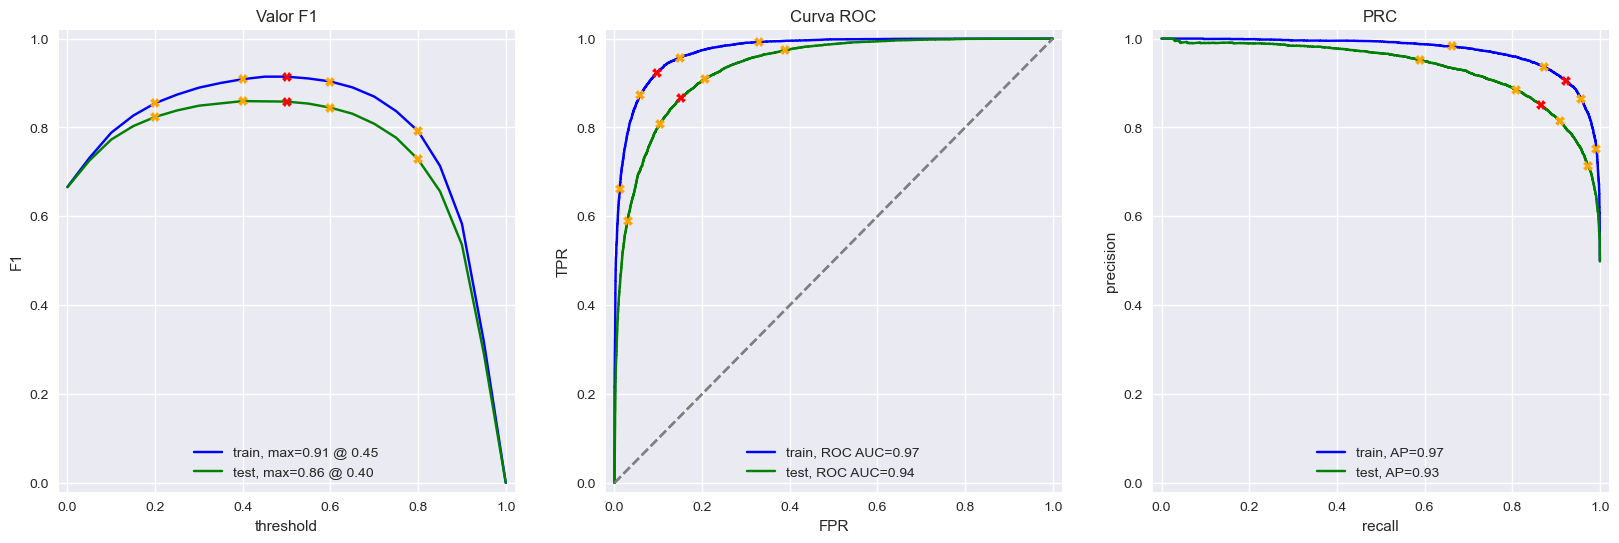

In [53]:
# Se instancia el clasificador LightGBM (LGBMClassifier), un modelo basado en potenciación de gradiente (Gradient Boosting)
model_3 = LGBMClassifier()
# Se entrena el modelo de LightGBM utilizando las características numéricas de TF-IDF y el objetivo de entrenamiento
model_3.fit(train_features, train_target)
# Se evalúa el desempeño final de LightGBM tanto en el conjunto de entrenamiento como en el de prueba,
# imprimiendo métricas esenciales como Accuracy, F1-Score y la Matriz de Confusión. 
evaluate_model(model_3, train_features, train_target, test_features, test_target)

Este modelo de clasificación, con la configuracion de modelo que tiene con LGBMClassifier tiene resultados que demuestran un rendimiento solido, balanceado y metodológicamente congruente, con reusltados muy similares al modelo anterior. Con respecto a F1-Score y Accuracy (Train: 0.91 / Test: 0.86): Una puntuación F1 del 86% en el conjunto de prueba es un resultado muy bueno para tareas complejas como el análisis de texto. El hecho de que el Accuracy y el F1-Score den exactamente el mismo número (0.91 en train y 0.86 en test) confirma de forma definitiva que las clases están perfectamente equilibradas (50/50). Por parte de ROC AUC y APS (Train: 0.97 / Test: 0.94): El Área Bajo la Curva ROC alcanza un notable 94% en los datos de prueba. Esto nos comunica que el modelo posee una excelente capacidad estadística para separar y discriminar entre las reseñas positivas y las negativas basándose en las probabilidades que calcula. 

Al comparar los resultados de prueba y entrenamiento se observa una caída de apenas 5 puntos porcentuales en el F1-Score (de 0.91 a 0.86) y de 3 puntos en el ROC AUC (de 0.97 a 0.94), visualmente, las líneas mantienen la misma geometría y corren casi en paralelo en los tres gráficos. El modelo no sufre de sobreajuste (overfitting) perjudicial. Ha logrado extraer reglas y patrones generales del lenguaje en lugar de memorizar el texto de entrenamiento. 

Este modelo actual es ligeramente inferior en precisión (pierde 2 puntos de F1 en test). Sin embargo, este modelo es matemáticamente más consistente, ya que el umbral óptimo (0.45) coincide de forma exacta tanto para los datos de entrenamiento como para los de prueba, lo que reduce la incertidumbre en su calibración.



## Reseñas propias <a id='my_review'></a>

In [92]:
# se prueban los modelos en las siguientes reseñas;

my_reviews = pd.DataFrame([
    'I did not simply like it, not my kind of movie.',
    'Well, I was bored and felt asleep in the middle of the movie.',
    'I was really fascinated with the movie',
    'Even the actors looked really old and disinterested, and they got paid to be in the movie. What a soulless cash grab.',
    'I didn\'t expect the reboot to be so good! Writers really cared about the source material',
    'The movie had its upsides and downsides, but I feel like overall it\'s a decent flick. I could see myself going to see it again.',
    'What a rotten attempt at a comedy. Not a single joke lands, everyone acts annoying and loud, even kids won\'t like this!',
    'Launching on Netflix was a brave move & I really appreciate being able to binge on episode after episode, of this exciting intelligent new drama.'
], columns=['review'])

"""
my_reviews = pd.DataFrame([
    'Simplemente no me gustó, no es mi tipo de película.',
    'Bueno, estaba aburrido y me quedé dormido a media película.',
    'Estaba realmente fascinada con la película',
    'Hasta los actores parecían muy viejos y desinteresados, y les pagaron por estar en la película. Qué robo tan desalmado.',
    '¡No esperaba que el relanzamiento fuera tan bueno! Los escritores realmente se preocuparon por el material original',
    'La película tuvo sus altibajos, pero siento que, en general, es una película decente. Sí la volvería a ver',
    'Qué pésimo intento de comedia. Ni una sola broma tiene sentido, todos actúan de forma irritante y ruidosa, ¡ni siquiera a los niños les gustará esto!',
    'Fue muy valiente el lanzamiento en Netflix y realmente aprecio poder seguir viendo episodio tras episodio de este nuevo drama tan emocionante e inteligente.'
], columns=['review'])
"""

my_reviews['review_norm'] = my_reviews['review'].str.lower().apply(lambda fila: re.sub(r'[^a-z]', ' ', fila))# <escribe aquí la misma lógica de normalización que para el conjunto de datos principal>

my_reviews

,review,review_norm
0,"I did not simply like it, not my kind of movie.",i did not simply like it not my kind of movie
1,"Well, I was bored and felt asleep in the middl...",well i was bored and felt asleep in the middl...
2,I was really fascinated with the movie,i was really fascinated with the movie
3,Even the actors looked really old and disinter...,even the actors looked really old and disinter...
4,I didn't expect the reboot to be so good! Writ...,i didn t expect the reboot to be so good writ...
5,"The movie had its upsides and downsides, but I...",the movie had its upsides and downsides but i...
6,What a rotten attempt at a comedy. Not a singl...,what a rotten attempt at a comedy not a singl...
7,Launching on Netflix was a brave move & I real...,launching on netflix was a brave move i real...


### Prueba modelo 1 <a id='proveM1'></a>

In [95]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_1.predict_proba(vectorizador_1.transform(texts))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.14:  i did not simply like it  not my kind of movie 
0.15:  well  i was bored and felt asleep in the middle of the movie 
0.53:  i was really fascinated with the movie
0.11:  even the actors looked really old and disinterested  and they got paid to be in the movie  what a so
0.30:  i didn t expect the reboot to be so good  writers really cared about the source material
0.47:  the movie had its upsides and downsides  but i feel like overall it s a decent flick  i could see my
0.04:  what a rotten attempt at a comedy  not a single joke lands  everyone acts annoying and loud  even ki
0.82:  launching on netflix was a brave move   i really appreciate being able to binge on episode after epi


El modelo 1 compuesto por NLTK, TF-IDF y LR, al tener un score F1 y Accuracy de 0.88 efectivamente tiene una buena aproximación en las reseñas, en este caso solo dos reseñas positivas podrian tener una mejor calificacion de la que la predicción les dio, sin embargo en el resto de los casos es muy acertada la calificacion con respecto al comentario, por su parte la mayoria negativas.

### Prueba modelo 2 <a id='proveM3'></a>

In [96]:
texts = my_reviews['review_norm']

my_reviews_pred_prob = model_2.predict_proba(vectorizador_2.transform(texts.apply(lambda x: text_preprocessing_2(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.20:  i did not simply like it  not my kind of movie 
0.15:  well  i was bored and felt asleep in the middle of the movie 
0.59:  i was really fascinated with the movie
0.10:  even the actors looked really old and disinterested  and they got paid to be in the movie  what a so
0.26:  i didn t expect the reboot to be so good  writers really cared about the source material
0.51:  the movie had its upsides and downsides  but i feel like overall it s a decent flick  i could see my
0.04:  what a rotten attempt at a comedy  not a single joke lands  everyone acts annoying and loud  even ki
0.92:  launching on netflix was a brave move   i really appreciate being able to binge on episode after epi


El modelo 2 esta compuesto por spaCy, TF-IDF y LR, si por un lado tien una mejor calificacion en "i was really fascinated with the movie" que el modelo 2  por 6 puntos, por otro lado a 'i didn t expect the reboot to be so good  writers really cared about the source material' el modelo le dio una calificación 0.26 lo cual es 4 puntos por debajo del modelo 2, por ultimo el comentario de "launching on netflix was a brave move   i really appreciate being able to binge on episode..." tiene una calificacion de 0.92 lo cual es bastante atinado al comentario. Este modelo obtuvo un score F1 y score de 0.88 mismo que el modelo 1, sin embargo en comparación esta predicción es mas acorde para el modelo 2.

### Prueba modelo 3 <a id='proveM4'>

In [97]:
texts = my_reviews['review_norm']

vectorizador_3 = vectorizador_3
my_reviews_pred_prob = model_3.predict_proba(vectorizador_3.transform(texts.apply(lambda x: text_preprocessing_3(x))))[:, 1]

for i, review in enumerate(texts.str.slice(0, 100)):
    print(f'{my_reviews_pred_prob[i]:.2f}:  {review}')

0.55:  i did not simply like it  not my kind of movie 
0.51:  well  i was bored and felt asleep in the middle of the movie 
0.60:  i was really fascinated with the movie
0.33:  even the actors looked really old and disinterested  and they got paid to be in the movie  what a so
0.67:  i didn t expect the reboot to be so good  writers really cared about the source material
0.65:  the movie had its upsides and downsides  but i feel like overall it s a decent flick  i could see my
0.21:  what a rotten attempt at a comedy  not a single joke lands  everyone acts annoying and loud  even ki
0.76:  launching on netflix was a brave move   i really appreciate being able to binge on episode after epi


El modelo 3 esta compuesto por spaCy, TF-IDF y LGBMClassifier, en esta ocasión el modelo otorgó calificaciones ligeramente mas altas que los anterirores modelos, fue un modelo menos pesimista sin embargo la en cuanto a una reseña realemtene positiva como es 'launching on netflix was a brave move   i really appreciate being able to binge on episode after epi' le pone una calificacion de 0.76 cuando los otros modelos le ponen una calificacion de 0.82 o 0.92, no existe un rango amplio en la calificacion que le da a las reseñas, esto sumado a que el modelo obtuvo un score F1 de 0.86 ligeramente inferior a los anteriores modelos al igual que en su resultado de AUC-ROC el cual de de 0.94 inferior igual a los otros modelos. 

## Conclusiones <a id='end'></a>

Los modelos de machine learning ayudaron a automatizar el asignar una calificación numérica a reseñas de películas y asi conocer si fue bien recibida por el público o no. Se compararon tres modelos, todos tuvieon un score  F1 mayor a 0.85 y un AUCROC mayor a 0.94 lo cual nos habla de modelos con excelente capacidad estadística para separar y discriminar entre las reseñas positivas y las negativas basándose en las probabilidades que calculan. La mejor configuracion de modelo fue con spaCy, TF-IDF y LR, y esto se pudo observar en las predicciones que hizo con reseñas externas. Se logro el objetivo de detectar reseñas negativas automáticamente.

En este proyecto se evaluarion tres modelos predictivos que analizaron textos, se utilizaron herramientas de lematizacion de palabras al reducirlas a su raiz mas simple, de forma que los datasets de palabras se redujeron, para despues ser convertido a un valor numérico en matriz dependiendo de su importancia y repetición dentro de las reseñas. Con estos valores numéricos y poder ingresar a un modelo. Se pudo contrastar una limpieza de textos basica como es NLTK contra una mas avanzada como spaCy, de forma que el tamaño conjunto de palabras que tenemos resulta ser mayor con NLTK, por otro lado, con spaCy se tiene mayormente compactada los grupos de parabras. En cuanto al tipo de clasificador, la regresión linear como su nombre lo indica lo realiza de manera lineal asignando pesos directo a las palabras o lemas, mientras que LightGBM no es lineal y asigna valor mas bien desde arboles de desición que tienen combinaciones mas complejas. Por parte del tiempo de entrenamiento debido a LightGBM utiliza matrices dispersas de textos se hace mayor el tiempo de ejecución, mientras que en por parte de spaCy y regresión logaritmicas la lematización es la que lleva mas tiempo pero menos en comparacion con LightGBM, por último el menor tiempo de ejecución es con NLTK y regresión logistica.
